<a id="project-menu" name="project-menu"></a>

# Real Estate Sale Price Prediction

**ITAI 1371 · Introduction to Machine Learning**

Put `real_estate_midterm_raw.csv` in the notebook's working folder. Run the notebook from top to bottom to reproduce both parts. In Colab, the Table of contents panel also lists the section headings.

## Project menu

- [Midterm · Exploratory Data Analysis and Preprocessing](#midterm)
- [Final Exam · Model Training, Validation and Comparison](#final)
- [1. Load the working CSV](#load)
- [2. Split into Train, Validation, and Test](#split)
- [3. Prepare the features](#prep)
- [4. Linear Regression](#linear)
- [5. Decision Tree Regressor](#tree)
- [6. Random Forest Regressor](#forest)
- [7. Gradient Boosting Regressor](#boosting)
- [8. K-Nearest Neighbors Regressor](#knn)
- [9. Compare the base models and select the best three](#validation)
- [10. Voting Regressor](#voting)
- [11. Bayesian ensemble](#bayesian)
- [12. Evaluate on Test and compare all models](#test)
- [13. Plot Validation vs. Test](#plots)
- [14. Best and worst model analysis](#analysis)
- [15. Final conclusion](#conclusion)

<a id="midterm" name="midterm"></a>

## Midterm · Exploratory Data Analysis and Preprocessing

This empty cell was part of the original Midterm and has no code to run.

# Midterm Project – Real Estate Exploratory Data Analysis and Preprocessing

**Course:** ITAI 1371 – Introduction to Machine Learning  
**Dataset Source:** Kaggle  
**Dataset:** Real Estate Sales  
**Original Dataset URL:** https://www.kaggle.com/datasets/nrng19/real-estate

## Project Goal

The goal of this project is to explore, clean, and preprocess a real estate dataset using Python.

For this Midterm, `real_estate_midterm_raw.csv` will be treated as the raw working dataset. All data preparation will be performed using Python without manually changing the dataset.

The dataset will first be divided into 70% training data and 30% testing data. Exploratory Data Analysis and preprocessing will be performed only on the training data, while the testing data will remain untouched.

The future machine learning goal is to predict **Sale Amount**, making this a **Supervised Learning – Regression** problem.

Load the working CSV and preview the rows, column names, and dataset size.

In [4]:
# 1. Load Data and Create Training and Testing Sets

#This section loads the raw working dataset and reviews its basic structure.
#The dataset is then divided into 70% training data and 30% testing data before any EDA or preprocessing is performed.
#The testing dataset is saved immediately and will remain untouched.


# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Load the raw working dataset

df = pd.read_csv("real_estate_midterm_raw.csv")

print("Dataset loaded successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nSample Data:")
display(df.head())

Dataset loaded successfully!

Dataset Shape:
(25000, 10)

Column Names:
['Serial Number', 'List Year', 'Date Recorded', 'Town', 'Address', 'Assessed Value', 'Sale Amount', 'Sales Ratio', 'Property Type', 'Residential Type']

Sample Data:


,Serial Number,List Year,Date Recorded,Town,Address,Assessed Value,Sale Amount,Sales Ratio,Property Type,Residential Type
0,18364,2018,09/03/2019,North Haven,67 MONTOWESE AVE,148960.0,202000.0,0.737400,Single Family,Single Family
1,21218,2021,04/25/2022,Bethel,526 COPPER SQUARE DRIVE,212730.0,382000.0,0.556800,Residential,Condo
2,80487,2008,07/31/2009,Fairfield,245 UNQUOWA ROAD #109,206220.0,325000.0,0.634523,Condo,Condo
3,70264,2007,08/15/2008,Darien,248 NOROTON AVE,423430.0,1137100.0,0.372377,Single Family,Single Family
4,200945,2020,05/27/2021,New Haven,86 OAK RDIGE DR # 38,26670.0,75000.0,0.355600,Residential,Condo


Create the original Midterm's 70% training and 30% testing split and save both raw subsets.

In [5]:
# Split dataset into 70% training and 30% testing

train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)

# Reset indexes

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


print("Training Data:")
print(train_df.shape)

print("\nTesting Data:")
print(test_df.shape)


# Save both raw datasets

train_df.to_csv("raw_train_data.csv", index=False)
test_df.to_csv("raw_test_data.csv", index=False)

print("\nTraining and testing datasets saved.")

Training Data:
(17500, 10)

Testing Data:
(7500, 10)

Training and testing datasets saved.


Explore the Midterm training rows for missing values, duplicates, and the distribution of sale amounts.

Training Dataset Shape:
(17500, 10)

Sample Training Data:


,Serial Number,List Year,Date Recorded,Town,Address,Assessed Value,Sale Amount,Sales Ratio,Property Type,Residential Type
0,200056,2020,11/23/2020,Westbrook,15 CHERRY ST,303850.0,300000.0,1.012800,Residential,Single Family
1,130172,2013,01/02/2014,Manchester,454-4 EAST CENTER STREET,47600.0,65000.0,0.732308,Condo,Condo
2,120221,2012,06/20/2013,Guilford,132 SCHOOLSIDE LN,372990.0,499000.0,0.747475,Single Family,Single Family
3,20042,2002,01/07/2003,Canterbury,BARSTOW RD,18800.0,42000.0,0.447619,NaN,NaN
4,130492,2013,06/03/2014,New Britain,529 CORBIN AVE,131460.0,240000.0,0.547750,Single Family,Single Family



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17500 entries, 0 to 17499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Serial Number     17500 non-null  int64  
 1   List Year         17500 non-null  int64  
 2   Date Recorded     17500 non-null  object 
 3   Town              17500 non-null  object 
 4   Address           17498 non-null  object 
 5   Assessed Value    17500 non-null  float64
 6   Sale Amount       17500 non-null  float64
 7   Sales Ratio       17500 non-null  float64
 8   Property Type     10924 non-null  object 
 9   Residential Type  10703 non-null  object 
dtypes: float64(3), int64(2), object(5)
memory usage: 1.3+ MB
Missing Values Before Cleaning:
Serial Number          0
List Year              0
Date Recorded          0
Town                   0
Address                2
Assessed Value         0
Sale Amount            0
Sales Ratio            0
Property Ty

,Serial Number,List Year,Assessed Value,Sale Amount,Sales Ratio
count,1.750000e+04,17500.000000,1.750000e+04,1.750000e+04,17500.000000
mean,4.162330e+05,2010.303257,2.817043e+05,4.051976e+05,1.796011
std,5.831941e+06,6.438612,1.406472e+06,1.775229e+06,31.686078
min,8.110000e+02,2001.000000,0.000000e+00,0.000000e+00,0.000000
25%,3.042850e+04,2004.000000,8.750000e+04,1.400000e+05,0.477763
50%,7.018900e+04,2010.000000,1.377250e+05,2.275000e+05,0.612000
75%,1.600320e+05,2016.000000,2.231150e+05,3.700000e+05,0.776059
max,2.111000e+08,2021.000000,6.023185e+07,1.523841e+08,3313.706667


Numerical Columns:
Index(['Serial Number', 'List Year', 'Assessed Value', 'Sale Amount',
       'Sales Ratio'],
      dtype='object')

Categorical Columns:
Index(['Date Recorded', 'Town', 'Address', 'Property Type',
       'Residential Type'],
      dtype='object')


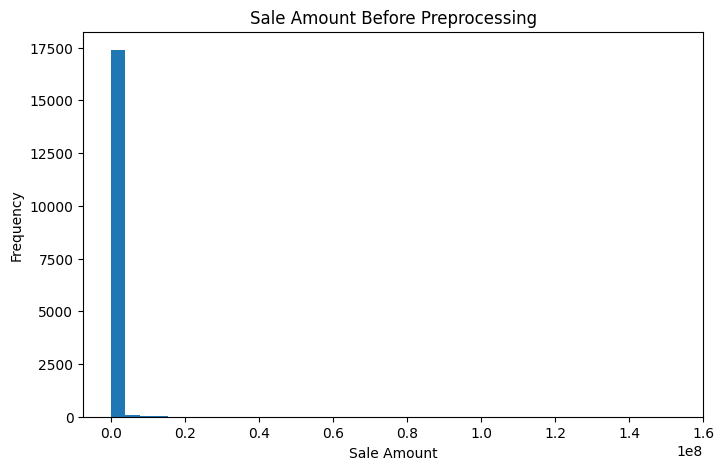

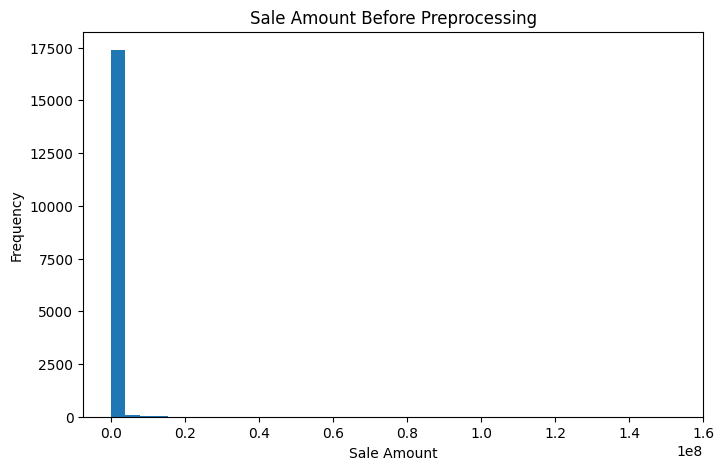

In [6]:
# 2. Exploratory Data Analysis – Training Data Only
#This section explores the training dataset before cleaning.
#We review the data structure, missing values, duplicates, numerical statistics, categorical features, and the distribution of important numerical variables.
#These observations will help determine what preprocessing is necessary.

# Review training data

print("Training Dataset Shape:")
print(train_df.shape)

print("\nSample Training Data:")
display(train_df.head())


# Review data types and non-null values

print("\nDataset Information:")
train_df.info()


# Check missing values

print("Missing Values Before Cleaning:")

print(
    train_df.isnull().sum()
)


# Check duplicate records

print("\nDuplicate Rows:")

print(
    train_df.duplicated().sum()
)


# Review numerical statistics

display(
    train_df.describe()
)

# Identify numerical and categorical columns

numerical_columns = train_df.select_dtypes(
    include="number"
).columns

categorical_columns = train_df.select_dtypes(
    include="object"
).columns


print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

# Visualize Sale Amount before preprocessing

plt.figure(figsize=(8, 5))

plt.hist(
    train_df["Sale Amount"].dropna(),
    bins=40
)

plt.title("Sale Amount Before Preprocessing")
plt.xlabel("Sale Amount")
plt.ylabel("Frequency")

plt.show()

# Visualize Sale Amount before preprocessing

plt.figure(figsize=(8, 5))

plt.hist(
    train_df["Sale Amount"].dropna(),
    bins=40
)

plt.title("Sale Amount Before Preprocessing")
plt.xlabel("Sale Amount")
plt.ylabel("Frequency")

plt.show()

Remove duplicate and invalid sale records from Midterm Train. Use the training median for invalid assessed values and fill missing categories with `Unknown`.

In [7]:
# 3. Data Cleaning and Feature Engineering

#This section cleans the training dataset based on the problems identified during EDA.
#The process includes:
#- Removing duplicate records
#- Handling missing values
#- Checking invalid numerical values
#- Creating new features from Date Recorded
#- Removing features that are not useful for the future machine learning model

# Create a copy of the training data for cleaning

train_clean = train_df.copy()


# Remove duplicate records

train_clean = train_clean.drop_duplicates()

print("Duplicates After Cleaning:")
print(train_clean.duplicated().sum())

# Check invalid numerical values

print("Invalid Sale Amount:")
print(
    (train_clean["Sale Amount"] <= 0).sum()
)

print("\nInvalid Assessed Value:")
print(
    (train_clean["Assessed Value"] <= 0).sum()
)


# Remove missing or invalid Sale Amount records from TRAINING data

train_clean = train_clean.dropna(
    subset=["Sale Amount"]
)

train_clean = train_clean[
    train_clean["Sale Amount"] > 0
].copy()


print("Training Shape After Sale Amount Cleaning:")
print(train_clean.shape)

# Convert invalid Assessed Value records to missing values

train_clean.loc[
    train_clean["Assessed Value"] <= 0,
    "Assessed Value"
] = np.nan


# Calculate the median using training data

assessed_median = train_clean[
    "Assessed Value"
].median()


# Fill missing values with the median

train_clean["Assessed Value"] = (
    train_clean["Assessed Value"]
    .fillna(assessed_median)
)


print("Median Assessed Value:")
print(assessed_median)

print("\nMissing Assessed Values After Cleaning:")
print(
    train_clean["Assessed Value"]
    .isnull()
    .sum()
)

# Fill missing categorical values

train_clean["Town"] = (
    train_clean["Town"]
    .fillna("Unknown")
)

train_clean["Property Type"] = (
    train_clean["Property Type"]
    .fillna("Unknown")
)

train_clean["Residential Type"] = (
    train_clean["Residential Type"]
    .fillna("Unknown")
)


print("Missing Categorical Values:")

print(
    train_clean[
        [
            "Town",
            "Property Type",
            "Residential Type"
        ]
    ].isnull().sum()
)

Duplicates After Cleaning:
0
Invalid Sale Amount:
23

Invalid Assessed Value:
117
Training Shape After Sale Amount Cleaning:
(17477, 10)
Median Assessed Value:
138320.0

Missing Assessed Values After Cleaning:
0
Missing Categorical Values:
Town                0
Property Type       0
Residential Type    0
dtype: int64


Extract the sale year and month from the recorded date and fill missing date parts with their most common training values.

In [8]:
### Feature Engineering

#The original `Date Recorded` column contains useful information.
#Sale Year and Sale Month are created from this column so the date information can later be used more easily by a machine learning model.

# Convert Date Recorded to datetime

train_clean["Date Recorded"] = pd.to_datetime(
    train_clean["Date Recorded"],
    errors="coerce"
)


# Create new date features

train_clean["Sale Year"] = (
    train_clean["Date Recorded"].dt.year
)

train_clean["Sale Month"] = (
    train_clean["Date Recorded"].dt.month
)


display(
    train_clean[
        [
            "Date Recorded",
            "Sale Year",
            "Sale Month"
        ]
    ].head()
)

# Fill missing year and month with the most common value

train_clean["Sale Year"] = (
    train_clean["Sale Year"]
    .fillna(
        train_clean["Sale Year"].mode()[0]
    )
)

train_clean["Sale Month"] = (
    train_clean["Sale Month"]
    .fillna(
        train_clean["Sale Month"].mode()[0]
    )
)



,Date Recorded,Sale Year,Sale Month
0,2020-11-23,2020,11
1,2014-01-02,2014,1
2,2013-06-20,2013,6
3,2003-01-07,2003,1
4,2014-06-03,2014,6


Remove identifiers and unused fields. Sales Ratio would reveal information about the sale price.

In [9]:
# Feature Selection

#Some original columns will not be useful for the future machine learning model.

#- `Serial Number` is only an identifier.
#- `Address` contains many unique text values.
#- `Date Recorded` has been replaced by Sale Year and Sale Month.
#- `Sales Ratio` is directly related to Sale Amount and could introduce data leakage.

# Remove unnecessary features

train_clean = train_clean.drop(
    columns=[
        "Serial Number",
        "Address",
        "Date Recorded",
        "Sales Ratio"
    ]
)


print("Remaining Columns:")

print(
    train_clean.columns.tolist()
)

display(train_clean.head())



Remaining Columns:
['List Year', 'Town', 'Assessed Value', 'Sale Amount', 'Property Type', 'Residential Type', 'Sale Year', 'Sale Month']


,List Year,Town,Assessed Value,Sale Amount,Property Type,Residential Type,Sale Year,Sale Month
0,2020,Westbrook,303850.0,300000.0,Residential,Single Family,2020,11
1,2013,Manchester,47600.0,65000.0,Condo,Condo,2014,1
2,2012,Guilford,372990.0,499000.0,Single Family,Single Family,2013,6
3,2002,Canterbury,18800.0,42000.0,Unknown,Unknown,2003,1
4,2013,New Britain,131460.0,240000.0,Single Family,Single Family,2014,6


Log-transform and scale Assessed Value. The histograms show how these steps change its distribution.

Before and After Normalization:


,Assessed Value,Assessed Value Log
0,303850.0,12.624293
1,47600.0,10.770609
2,372990.0,12.829310
3,18800.0,9.841665
4,131460.0,11.786466


,Assessed Value,Assessed Value Log,Assessed Value Scaled
0,303850.0,12.624293,0.781970
1,47600.0,10.770609,-1.133924
2,372990.0,12.829310,0.993867
3,18800.0,9.841665,-2.094043
4,131460.0,11.786466,-0.083975


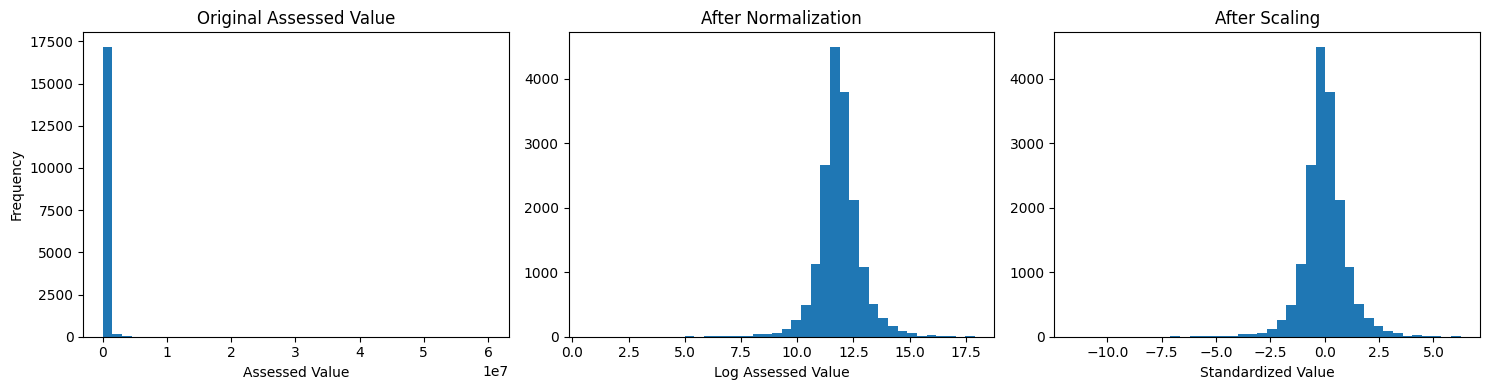

In [15]:
# 4. Data Transformation
# This section prepares the cleaned training dataset for future machine learning.
#The process includes:
#- Normalization
#- Feature Scaling
#- One-Hot Encoding
#These transformations are performed only on the training data.

# Apply log normalization to Assessed Value

train_clean["Assessed Value Log"] = np.log1p(
    train_clean["Assessed Value"]
)


print("Before and After Normalization:")

display(
    train_clean[
        [
            "Assessed Value",
            "Assessed Value Log"
        ]
    ].head()
)

# Create StandardScaler

scaler = StandardScaler()


# Scale the normalized Assessed Value

train_clean["Assessed Value Scaled"] = (
    scaler.fit_transform(
        train_clean[
            ["Assessed Value Log"]
        ]
    )
)


display(
    train_clean[
        [
            "Assessed Value",
            "Assessed Value Log",
            "Assessed Value Scaled"
        ]
    ].head()
)

# Compare Assessed Value before and after preprocessing

plt.figure(figsize=(15, 4))


# Original distribution

plt.subplot(1, 3, 1)

plt.hist(
    train_clean["Assessed Value"],
    bins=40
)

plt.title("Original Assessed Value")
plt.xlabel("Assessed Value")
plt.ylabel("Frequency")


# Normalized distribution

plt.subplot(1, 3, 2)

plt.hist(
    train_clean["Assessed Value Log"],
    bins=40
)

plt.title("After Normalization")
plt.xlabel("Log Assessed Value")


# Scaled distribution

plt.subplot(1, 3, 3)

plt.hist(
    train_clean["Assessed Value Scaled"],
    bins=40
)

plt.title("After Scaling")
plt.xlabel("Standardized Value")


plt.tight_layout()
plt.show()




Turn town and property categories into indicator columns and keep the scaled version of Assessed Value.

In [11]:
# One-Hot Encoding
#Categorical text features need to be converted into numerical values before they can later be used by machine learning models.
# One-Hot Encoding is applied to Town, Property Type, and Residential Type.

# Apply One-Hot Encoding

train_encoded = pd.get_dummies(
    train_clean,
    columns=[
        "Town",
        "Property Type",
        "Residential Type"
    ],
    drop_first=True,
    dtype=int
)


print("Shape Before Encoding:")
print(train_clean.shape)

print("\nShape After Encoding:")
print(train_encoded.shape)


display(train_encoded.head())


# Keep the final scaled version of Assessed Value

train_encoded = train_encoded.drop(
    columns=[
        "Assessed Value",
        "Assessed Value Log"
    ]
)


print("Final Columns:")
print(train_encoded.columns.tolist())


Shape Before Encoding:
(17477, 10)

Shape After Encoding:
(17477, 190)


,List Year,Assessed Value,Sale Amount,Sale Year,Sale Month,Assessed Value Log,Assessed Value Scaled,Town_Ansonia,Town_Ashford,Town_Avon,...,Property Type_Single Family,Property Type_Three Family,Property Type_Two Family,Property Type_Unknown,Property Type_Vacant Land,Residential Type_Four Family,Residential Type_Single Family,Residential Type_Three Family,Residential Type_Two Family,Residential Type_Unknown
0,2020,303850.0,300000.0,2020,11,12.624293,0.781970,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1,2013,47600.0,65000.0,2014,1,10.770609,-1.133924,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2012,372990.0,499000.0,2013,6,12.829310,0.993867,0,0,0,...,1,0,0,0,0,0,1,0,0,0
3,2002,18800.0,42000.0,2003,1,9.841665,-2.094043,0,0,0,...,0,0,0,1,0,0,0,0,0,1
4,2013,131460.0,240000.0,2014,6,11.786466,-0.083975,0,0,0,...,1,0,0,0,0,0,1,0,0,0


Final Columns:
['List Year', 'Sale Amount', 'Sale Year', 'Sale Month', 'Assessed Value Scaled', 'Town_Ansonia', 'Town_Ashford', 'Town_Avon', 'Town_Barkhamsted', 'Town_Beacon Falls', 'Town_Berlin', 'Town_Bethany', 'Town_Bethel', 'Town_Bethlehem', 'Town_Bloomfield', 'Town_Bolton', 'Town_Bozrah', 'Town_Branford', 'Town_Bridgeport', 'Town_Bridgewater', 'Town_Bristol', 'Town_Brookfield', 'Town_Brooklyn', 'Town_Burlington', 'Town_Canaan', 'Town_Canterbury', 'Town_Canton', 'Town_Chaplin', 'Town_Cheshire', 'Town_Chester', 'Town_Clinton', 'Town_Colchester', 'Town_Colebrook', 'Town_Columbia', 'Town_Cornwall', 'Town_Coventry', 'Town_Cromwell', 'Town_Danbury', 'Town_Darien', 'Town_Deep River', 'Town_Derby', 'Town_Durham', 'Town_East Granby', 'Town_East Haddam', 'Town_East Hampton', 'Town_East Hartford', 'Town_East Haven', 'Town_East Lyme', 'Town_East Windsor', 'Town_Eastford', 'Town_Easton', 'Town_Ellington', 'Town_Enfield', 'Town_Essex', 'Town_Fairfield', 'Town_Farmington', 'Town_Franklin', 'Town

Check the prepared Midterm training data for missing values and text columns.

In [12]:
# 5. Final Data Quality Check and Export
# The processed training dataset is reviewed to confirm that the required preprocessing steps have been completed.
# The final clean dataset will then be saved for future machine learning exercises.

# Final quality check

print("Final Training Dataset Shape:")
print(train_encoded.shape)


print("\nTotal Missing Values:")
print(
    train_encoded.isnull().sum().sum()
)


print("\nRemaining Text Columns:")
print(
    train_encoded
    .select_dtypes(include="object")
    .columns
    .tolist()
)


print("\nFinal Sample Data:")
display(train_encoded.head())

Final Training Dataset Shape:
(17477, 188)

Total Missing Values:
0

Remaining Text Columns:
[]

Final Sample Data:


,List Year,Sale Amount,Sale Year,Sale Month,Assessed Value Scaled,Town_Ansonia,Town_Ashford,Town_Avon,Town_Barkhamsted,Town_Beacon Falls,...,Property Type_Single Family,Property Type_Three Family,Property Type_Two Family,Property Type_Unknown,Property Type_Vacant Land,Residential Type_Four Family,Residential Type_Single Family,Residential Type_Three Family,Residential Type_Two Family,Residential Type_Unknown
0,2020,300000.0,2020,11,0.781970,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1,2013,65000.0,2014,1,-1.133924,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2012,499000.0,2013,6,0.993867,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0
3,2002,42000.0,2003,1,-2.094043,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
4,2013,240000.0,2014,6,-0.083975,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0


Compare training data before and after preprocessing, then save the prepared Midterm training data.

In [13]:
# Compare training data before and after preprocessing

print("BEFORE PREPROCESSING")

print("Shape:")
print(train_df.shape)

print("Missing Values:")
print(
    train_df.isnull().sum().sum()
)


print("\n-----------------------")


print("\nAFTER PREPROCESSING")

print("Shape:")
print(train_encoded.shape)

print("Missing Values:")
print(
    train_encoded.isnull().sum().sum()
)

# Save final cleaned training dataset

train_encoded.to_csv(
    "cleaned_train_data.csv",
    index=False
)


print("Cleaned training dataset saved successfully.")

print("Final Shape:")
print(train_encoded.shape)

BEFORE PREPROCESSING
Shape:
(17500, 10)
Missing Values:
13375

-----------------------

AFTER PREPROCESSING
Shape:
(17477, 188)
Missing Values:
0
Cleaned training dataset saved successfully.
Final Shape:
(17477, 188)


## Objective

The future goal will be to predict the sale price of a property using property and transaction characteristics.

Potential predictor features include:

- Assessed Value
- Town
- Property Type
- Residential Type
- List Year
- Sale Year
- Sale Month

`Sales Ratio` was excluded because it is directly related to Sale Amount and could introduce data leakage.

The cleaned training dataset can later be used to train and compare regression models.

The 30% testing dataset remained untouched during the Midterm and can later be prepared using the same rules learned from training data and used to evaluate the final machine learning models.

# Project Summary

For this Midterm, the Real Estate dataset was divided into 70% training data and 30% testing data before Exploratory Data Analysis.

All EDA and preprocessing were performed only on the training dataset.

The preprocessing included:

- Missing value handling
- Duplicate checking
- Invalid value checking
- Feature engineering
- Feature selection
- Normalization
- Feature scaling
- One-Hot Encoding
- Before and after visualizations

Class balancing was reviewed but was not applicable because this is a regression problem.

The testing dataset remained untouched.

<a id="final" name="final"></a>

# FINAL EXAM – MODEL TRAINING, VALIDATION AND COMPARISON

The goal is to predict **Sale Amount** in dollars. This section starts from the raw working CSV and uses its own 70% Train, 15% Validation, and 15% Test split. Validation determines the top three base models and the final model choice. Test measures performance after those choices are fixed.

[Back to the project menu](#project-menu)

<a id="load" name="load"></a>

## 1. Load the working CSV

Import the tools for this part and read the same working CSV used in the Midterm.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import BayesianRidge, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

seed = 42
target = "Sale Amount"
final_raw = pd.read_csv("real_estate_midterm_raw.csv")
print(f"Working CSV: {len(final_raw):,} rows and {final_raw.shape[1]} columns")
print(f"Exact duplicate rows: {final_raw.duplicated().sum():,}")

Working CSV: 25,000 rows and 10 columns
Exact duplicate rows: 0


<a id="split" name="split"></a>

## 2. Split into Train, Validation, and Test

Set aside 30% of the raw rows and divide that portion equally into Validation and Test. The same seed makes the split reproducible.

In [17]:
final_train_raw, final_holdout = train_test_split(
    final_raw, test_size=0.30, random_state=seed
)
final_validation_raw, final_test_raw = train_test_split(
    final_holdout, test_size=0.50, random_state=seed
)

split_counts = pd.Series({
    "Train": len(final_train_raw),
    "Validation": len(final_validation_raw),
    "Test": len(final_test_raw),
})
display(pd.DataFrame({
    "Raw rows": split_counts,
    "Share of CSV": split_counts.div(len(final_raw)).map("{:.0%}".format),
}))

,Raw rows,Share of CSV
Train,17500,70%
Validation,3750,15%
Test,3750,15%


<a id="prep" name="prep"></a>

## 3. Prepare the features

Apply the Midterm's rule of keeping positive sale amounts. Extract the year and month from the date, mark invalid assessed values as missing, and select the predictor columns. Sales Ratio is derived from the sale price, so it is excluded to avoid data leakage.

In [18]:
categorical_features = ["Town", "Property Type", "Residential Type"]
year_month_features = ["List Year", "Sale Year", "Sale Month"]
predictors = ["Assessed Value"] + year_month_features + categorical_features


def prepare_sales(rows):
    rows = rows.drop_duplicates().copy()
    rows[target] = pd.to_numeric(rows[target], errors="coerce")
    rows = rows.loc[np.isfinite(rows[target]) & rows[target].gt(0)].copy()

    assessed = pd.to_numeric(rows["Assessed Value"], errors="coerce")
    rows["Assessed Value"] = assessed.where(np.isfinite(assessed) & assessed.gt(0))
    recorded = pd.to_datetime(rows["Date Recorded"], format="%m/%d/%Y", errors="coerce")
    rows["Sale Year"] = recorded.dt.year
    rows["Sale Month"] = recorded.dt.month
    return rows[predictors], rows[target]


X_train_final, y_train_final = prepare_sales(final_train_raw)
X_val_final, y_val_final = prepare_sales(final_validation_raw)
print(f"Train: {len(y_train_final):,} usable rows out of {len(final_train_raw):,}")
print(f"Validation: {len(y_val_final):,} usable rows out of {len(final_validation_raw):,}")

Train: 17,477 usable rows out of 17,500
Validation: 3,744 usable rows out of 3,750


Define how to fill missing values, transform assessed value, scale numeric features, and encode categories. Each model pipeline learns the fill values, scaling, and category columns when it fits on Train. Validation and Test use those learned settings. Scaling keeps numeric ranges from dominating KNN distances.

In [19]:
assessed_steps = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log1p),
    StandardScaler(),
)
date_steps = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    StandardScaler(),
)
category_steps = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="Unknown"),
    OneHotEncoder(handle_unknown="ignore"),
)

final_preprocessing = ColumnTransformer([
    ("assessed", assessed_steps, ["Assessed Value"]),
    ("dates", date_steps, year_month_features),
    ("categories", category_steps, categorical_features),
])

base_models = {}


def fit_base_model(name, regressor):
    pipeline = make_pipeline(clone(final_preprocessing), regressor)
    pipeline.fit(X_train_final, y_train_final)
    base_models[name] = pipeline
    print(f"{name} trained on {len(y_train_final):,} sales.")

<a id="linear" name="linear"></a>

## 4. Linear Regression

Fit a model that adds up the effects of the prepared features to predict sale price.

In [20]:
fit_base_model("Linear Regression", LinearRegression())

Linear Regression trained on 17,477 sales.


<a id="tree" name="tree"></a>

## 5. Decision Tree Regressor

Fit a single tree that splits properties into groups. Limit tree depth and require several sales per leaf to reduce overfitting.

In [21]:
fit_base_model(
    "Decision Tree Regressor",
    DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=seed),
)

Decision Tree Regressor trained on 17,477 sales.


<a id="forest" name="forest"></a>

## 6. Random Forest Regressor

Train many trees on different samples of Train and average their predictions.

In [22]:
fit_base_model(
    "Random Forest Regressor",
    RandomForestRegressor(
        n_estimators=80, max_depth=14, min_samples_leaf=3, random_state=seed, n_jobs=-1
    ),
)

Random Forest Regressor trained on 17,477 sales.


<a id="boosting" name="boosting"></a>

## 7. Gradient Boosting Regressor

Train trees in sequence so that each new tree helps correct errors from the earlier trees.

In [23]:
fit_base_model(
    "Gradient Boosting Regressor",
    GradientBoostingRegressor(random_state=seed),
)

Gradient Boosting Regressor trained on 17,477 sales.


<a id="knn" name="knn"></a>

## 8. K-Nearest Neighbors Regressor

Predict the sale price using the mean sale price of the 10 closest training properties in the prepared feature space.

In [24]:
fit_base_model("KNN Regressor", KNeighborsRegressor(n_neighbors=10))

KNN Regressor trained on 17,477 sales.


<a id="validation" name="validation"></a>

## 9. Compare the base models and select the best three

Score each base model on the same Validation rows. **MAE** is the average absolute error in dollars. **MSE** is in dollars squared and penalizes large errors more. **R²** measures performance relative to predicting the average sale price for the evaluated set. Lower MAE and MSE and higher R² are better. Select the three lowest Validation MAEs, using MSE to break a tie.

In [25]:
def regression_scores(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "R²": r2_score(actual, predicted),
    }


def rank_by_error(scores):
    return scores.sort_values(["MAE", "MSE"])


def show_metrics(scores):
    formatted = scores.copy()
    for column in scores.columns:
        number_format = "{:.4f}" if column.endswith("R²") else "{:,.2f}"
        formatted[column] = scores[column].map(number_format.format)
    display(formatted)


val_predictions = {
    name: model.predict(X_val_final) for name, model in base_models.items()
}
base_validation = rank_by_error(pd.DataFrame.from_dict({
    name: regression_scores(y_val_final, predicted)
    for name, predicted in val_predictions.items()
}, orient="index"))
top_three = base_validation.index[:3].tolist()
show_metrics(base_validation)
print("Selected base models:", ", ".join(top_three))

,MAE,MSE,R²
Gradient Boosting Regressor,"140,393.25","366,196,207,480.50",0.6790
Random Forest Regressor,"145,558.67","648,671,114,620.64",0.4315
Decision Tree Regressor,"158,928.33","1,052,249,287,169.21",0.0778
KNN Regressor,"173,075.40","753,936,443,595.84",0.3392
Linear Regression,"333,278.18","933,573,151,416.86",0.1818


Selected base models: Gradient Boosting Regressor, Random Forest Regressor, Decision Tree Regressor


<a id="voting" name="voting"></a>

## 10. Voting Regressor

Give the three selected models equal weight. Voting Regressor fits copies of those pipelines on Train and averages their price predictions.

In [26]:
voting_name = "Voting Regressor"
voting = VotingRegressor([
    (f"model_{index}", base_models[name])
    for index, name in enumerate(top_three, start=1)
])
voting.fit(X_train_final, y_train_final)
val_predictions[voting_name] = voting.predict(X_val_final)

<a id="bayesian" name="bayesian"></a>

## 11. Bayesian ensemble

Combine predictions from the same three models with Bayesian Ridge. To prepare the training data for the ensemble, split Train into three folds. Each row gets predictions from models whose preprocessing and fitting used the other two folds. These are called out-of-fold predictions.

In [27]:
folds = KFold(n_splits=3, shuffle=True, random_state=seed)
train_ensemble_inputs = pd.DataFrame({
    name: cross_val_predict(base_models[name], X_train_final, y_train_final, cv=folds)
    for name in top_three
})
display(train_ensemble_inputs.head().round(2))

,Gradient Boosting Regressor,Random Forest Regressor,Decision Tree Regressor
0,486659.07,450508.82,437659.65
1,149098.98,87069.07,94287.07
2,524936.45,488165.04,516611.11
3,142853.83,76721.60,82144.76
4,181078.51,166814.08,148320.72


Fit Bayesian Ridge to the three out-of-fold prediction columns. It starts with a prior that favors coefficients near zero and updates the coefficients using the training examples. It learns a weight for each prediction and an intercept. Compare the two ensembles on Validation before opening Test.

In [28]:
bayesian_name = "Bayesian Ridge Ensemble"
bayesian_ensemble = make_pipeline(StandardScaler(), BayesianRidge())
bayesian_ensemble.fit(train_ensemble_inputs, y_train_final)
validation_ensemble_inputs = pd.DataFrame({
    name: val_predictions[name] for name in top_three
})
val_predictions[bayesian_name] = bayesian_ensemble.predict(validation_ensemble_inputs)

all_validation = rank_by_error(pd.DataFrame.from_dict({
    name: regression_scores(y_val_final, predicted)
    for name, predicted in val_predictions.items()
}, orient="index"))
show_metrics(all_validation.loc[[voting_name, bayesian_name]])
selected_model = all_validation.index[0]
print("Final model selected by Validation MAE:", selected_model)

,MAE,MSE,R²
Voting Regressor,"142,282.71","567,756,657,739.88",0.5024
Bayesian Ridge Ensemble,"144,978.36","511,984,565,748.70",0.5513


Final model selected by Validation MAE: Gradient Boosting Regressor


<a id="test" name="test"></a>

## 12. Evaluate on Test and compare all models

Prepare the held-out Test rows and score all seven candidates on the same sales. The table keeps the Validation ranking so the selected model stays at the top.

In [29]:
X_test_final, y_test_final = prepare_sales(final_test_raw)
print(f"Test: {len(y_test_final):,} usable rows out of {len(final_test_raw):,}")

test_predictions = {
    name: model.predict(X_test_final) for name, model in base_models.items()
}
test_predictions[voting_name] = voting.predict(X_test_final)
test_ensemble_inputs = pd.DataFrame({
    name: test_predictions[name] for name in top_three
})
test_predictions[bayesian_name] = bayesian_ensemble.predict(test_ensemble_inputs)

all_test = pd.DataFrame.from_dict({
    name: regression_scores(y_test_final, predicted)
    for name, predicted in test_predictions.items()
}, orient="index")
comparison = all_validation.add_prefix("Validation ").join(all_test.add_prefix("Test "))
comparison.index.name = "Model"
show_metrics(comparison)

Test: 3,741 usable rows out of 3,750


,Validation MAE,Validation MSE,Validation R²,Test MAE,Test MSE,Test R²
Model,,,,,,
Gradient Boosting Regressor,"140,393.25","366,196,207,480.50",0.6790,"127,590.85","308,485,712,976.65",0.1188
Voting Regressor,"142,282.71","567,756,657,739.88",0.5024,"127,398.01","417,245,740,384.49",-0.1918
Bayesian Ridge Ensemble,"144,978.36","511,984,565,748.70",0.5513,"135,072.25","540,036,219,431.17",-0.5426
Random Forest Regressor,"145,558.67","648,671,114,620.64",0.4315,"128,396.41","401,394,250,167.33",-0.1466
Decision Tree Regressor,"158,928.33","1,052,249,287,169.21",0.0778,"148,035.84","1,189,567,796,784.97",-2.3980
KNN Regressor,"173,075.40","753,936,443,595.84",0.3392,"144,013.51","486,781,275,577.69",-0.3905
Linear Regression,"333,278.18","933,573,151,416.86",0.1818,"296,860.82","316,137,637,994.14",0.0970


Compare both ensembles on the same five Test sales to see how their price predictions differ. The full Test metrics above summarize the comparison across every eligible sale.

In [30]:
ensemble_example = pd.DataFrame({
    "Actual sale amount": y_test_final.to_numpy(),
    "Voting prediction": test_predictions[voting_name],
    "Bayesian prediction": test_predictions[bayesian_name],
})
display(ensemble_example.head().apply(lambda column: column.map("${:,.0f}".format)))

,Actual sale amount,Voting prediction,Bayesian prediction
0,"$135,000","$111,478","$98,656"
1,"$700,000","$779,668","$785,487"
2,"$230,000","$333,154","$413,957"
3,"$1,275,000","$1,326,064","$1,533,819"
4,"$299,000","$277,215","$264,299"


<a id="plots" name="plots"></a>

## 13. Plot Validation vs. Test

Plot Validation and Test side by side for each metric. Each panel uses its own units, and the order follows Validation MAE.

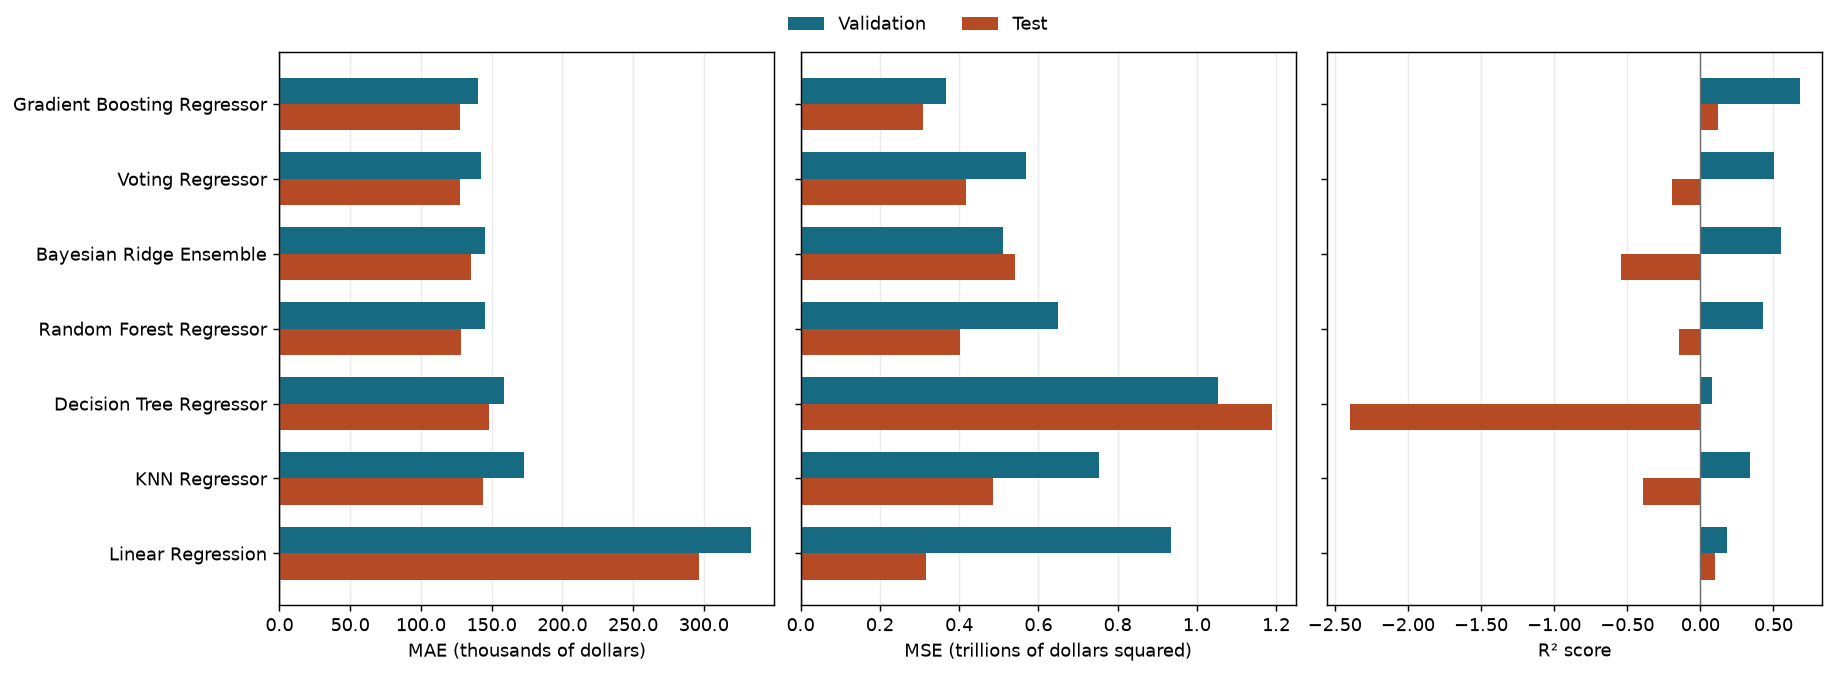

In [31]:
from matplotlib.ticker import StrMethodFormatter

fig, axes = plt.subplots(1, 3, figsize=(14, 5.1), sharey=True, layout="constrained")
positions = np.arange(len(comparison))
width = 0.35

for ax, (metric, label) in zip(axes, [
    ("MAE", "MAE (thousands of dollars)"),
    ("MSE", "MSE (trillions of dollars squared)"),
    ("R²", "R² score"),
]):
    divisor = {"MAE": 1_000, "MSE": 1_000_000_000_000, "R²": 1}[metric]
    ax.barh(positions - width / 2, comparison[f"Validation {metric}"] / divisor,
            height=width, color="#166A82", label="Validation")
    ax.barh(positions + width / 2, comparison[f"Test {metric}"] / divisor,
            height=width, color="#B64A24", label="Test")
    ax.set_xlabel(label)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}" if metric == "R²" else "{x:,.1f}"))
    ax.axvline(0, color="#707070", linewidth=0.8)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

axes[0].set_yticks(positions, comparison.index)
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False)
plt.show()

<a id="analysis" name="analysis"></a>

## 14. Best and worst model analysis

**Best by Validation MAE.** Gradient Boosting Regressor had the lowest Validation MAE (USD 140,393.25). On Test, its MAE was USD 127,590.85 and its R² was 0.119. It also had the lowest Test MSE and highest Test R². Voting Regressor had a Test MAE that was USD 192.85 lower.

**Worst by MAE.** Linear Regression had the highest Validation MAE (USD 333,278.18). Linear Regression also had the highest Test MAE (USD 296,860.82). Decision Tree Regressor had the highest Test MSE and lowest Test R² (-2.398). Its large errors show up more in the squared-error metrics.

**Ensemble comparison.** The three base models were Gradient Boosting Regressor, Random Forest Regressor, Decision Tree Regressor. Voting had lower MAE on Validation (USD 142,282.71 versus USD 144,978.36) and Test (USD 127,398.01 versus USD 135,072.25). Bayesian Ridge had lower Validation MSE and higher Validation R². On Test, Voting led the Bayesian ensemble on all three metrics.

**Validation vs. Test.** Gradient Boosting Regressor's R² fell from 0.679 to 0.119 even as MAE improved. R² depends on how much sale prices vary within each split. The highest sale was USD 39,354,839 in Validation and USD 21,930,000 in Test, so the two sets have different price ranges.

<a id="conclusion" name="conclusion"></a>

## 15. Final conclusion

Gradient Boosting Regressor is the final choice based on Validation MAE. Its held-out Test MAE of USD 127,590.85 and R² of 0.119 show that the predictions still have substantial error. The equal-weight ensemble had a slightly lower Test MAE, while the selected model had the lower Test MSE. These findings apply to positive-price sales in this working sample.

[Back to the project menu](#project-menu)